<a href="https://colab.research.google.com/github/inorganicnoise/KLASIFIKASI-SAMPAH-CNN/blob/sagithadamayantielsya-source-patch-1/revisi_project_sdg_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Jenis Sampah Menggunakan Convolutional Neural Network (CNN)

♻️ Project Deep Learning - SDGs 12: Konsumsi dan Produksi yang Bertanggung Jawab

Notebook ini berisi implementasi Convolutional Neural Network (CNN) menggunakan TensorFlow/Keras untuk mengklasifikasikan jenis sampah berdasarkan citra gambar sebagai pendukung pemilahan sampah di lingkungan kampus.

**Anggota Kelompok**

| No. | Nama | NIM |
|---|---|---|
| 1 | Elsya Sagitha Damayanti S | F1G125029 |
| 2 | Rahmah Hidayah L | F1G125047 |
| 3 | Ridha Septiani K | F1G125075 |

Program Studi Ilmu Komputer, FMIPA, Universitas Halu Oleo

**Sumber Data:** [RealWaste - Kaggle](https://www.kaggle.com/datasets/joebeachcapital/realwaste)

## **1. Pengumpulan Dataset**

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download('joebeachcapital/realwaste')

Using Colab cache for faster access to the 'realwaste' dataset.


In [ ]:
import os

dataset_folder = os.path.join(dataset_path,'realwaste-main', 'RealWaste')

for item in os.listdir(dataset_folder):
  print(item)


Metal
Glass
Paper
Vegetation
Cardboard
Textile Trash
Food Organics
Plastic
Miscellaneous Trash


In [ ]:
import shutil

selected_classes = ['Plastic', 'Paper', 'Metal', 'Food Organics']

filtered_folder = 'Realwaste_Selected'
os.makedirs(filtered_folder, exist_ok=True)

In [ ]:
for category in selected_classes:
  source = os.path.join(dataset_folder, category)
  destination = os.path.join(filtered_folder, category)

  if os.path.exists(destination):
    shutil.rmtree(destination)

  shutil.copytree(source, destination)

In [ ]:
for category in selected_classes:
  folder = os.path.join(filtered_folder, category)
  print(category, ":", len(os.listdir(folder)))

Plastic : 921
Paper : 500
Metal : 790
Food Organics : 411


## **2. Exploratory Data Analysis (EDA)**

EDA dilakukan untuk melihat jumlah gambar pada setiap kategori dan memahami kondisi dataset sebelum digunakan untuk pelatihan.

In [ ]:
for category in os.listdir(filtered_folder):
    print(category, ":", len(os.listdir(os.path.join(filtered_folder, category))))

Paper : 500
Plastic : 921
Metal : 790
Food Organics : 411


### Visualisasi Sampel Gambar

Menampilkan contoh gambar dari setiap kategori untuk melihat variasi bentuk dan tampilan sampah.

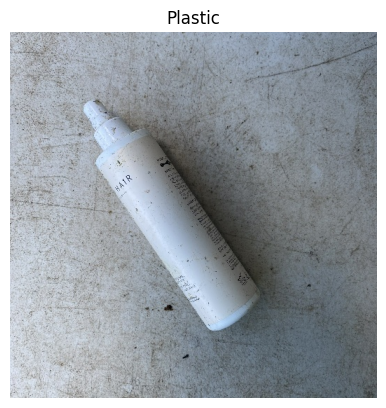

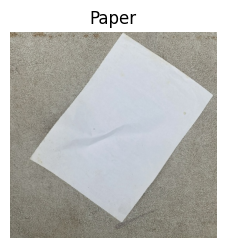

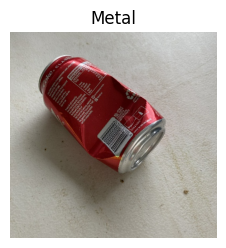

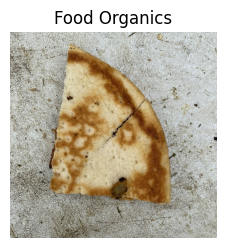

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(12, 8))

for i, category in enumerate(selected_classes):
  folder = os.path.join(filtered_folder, category)
  gambar = os.listdir(folder)[0]
  img = Image.open(os.path.join(folder, gambar))

  plt.subplot(2, 2, i + 1)
  plt.imshow(img)
  plt.title(category)
  plt.axis('off')
  plt.tight_layout()
  plt.show()

## **3. Pembagian Dataset**

Dataset dibagi menjadi tiga bagian menggunakan library `split-folders` dengan `seed=42` agar hasil pembagian dapat direproduksi:

| Bagian | Proporsi | Fungsi |
|---|---|---|
| Training Set | 70% | Melatih model |
| Validation Set | 15% | Memantau proses pelatihan |
| Testing Set | 15% | Menguji performa akhir model |

In [ ]:
!pip install -q split-folders

In [ ]:
import splitfolders
import shutil

if os.path.exists("dataset_split"): shutil.rmtree("dataset_split")

splitfolders.ratio(
    filtered_folder,
    output="dataset_split",
    seed=42,
    ratio=(0.7, 0.15, 0.15)
)

Copying files: 2622 files [00:01, 2267.66 files/s]


### Pemeriksaan Hasil Pembagian

Memeriksa jumlah gambar pada setiap kategori di data training, validation, dan testing.

In [ ]:
for folder in ['train', 'val', 'test']:
  print("\n",folder)

  for category in selected_classes:
    path = os.path.join("dataset_split", folder, category)
    total = len(os.listdir(path))
    print(category, ":", total)


 train
Plastic : 644
Paper : 350
Metal : 553
Food Organics : 287

 val
Plastic : 138
Paper : 75
Metal : 118
Food Organics : 61

 test
Plastic : 139
Paper : 75
Metal : 119
Food Organics : 63


## **4. Preprocessing Data**

### Memuat Dataset

Gambar dimuat dari folder dengan ukuran 224 × 224 piksel dan batch size 32. Label diperoleh dari nama folder. Data validation dan testing tidak diacak agar urutan label tetap sesuai saat evaluasi.


In [ ]:
import tensorflow as tf
import numpy as np

tf.keras.utils.set_random_seed(42)

train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset_split/train",
    image_size=(224, 224),
    batch_size=32,
    seed=42,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset_split/val",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset_split/test",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

Found 1834 files belonging to 4 classes.
Found 392 files belonging to 4 classes.
Found 396 files belonging to 4 classes.


In [ ]:
class_names = train_ds.class_names
print("Nama Kelas:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Nama Kelas: ['Food Organics', 'Metal', 'Paper', 'Plastic']


### Penyeimbangan Bobot Kelas

Bobot kelas dihitung berdasarkan jumlah gambar pada data training. Bobot ini digunakan saat pelatihan untuk membantu mengurangi pengaruh perbedaan jumlah gambar antar kategori.

In [ ]:
jumlah_per_kelas = [
    len(os.listdir(os.path.join("dataset_split", "train", k)))
    for k in class_names
]
total_train = sum(jumlah_per_kelas)

class_weights = {
    i: (total_train / (len(class_names) * n)) ** 0.5
    for i, n in enumerate(jumlah_per_kelas)
}

print("Class Weight:")
for i, weight in class_weights.items():
    print(f"{class_names[i]}: {weight:.3f}")

Class Weight:
Food Organics: 1.264
Metal: 0.911
Paper: 1.145
Plastic: 0.844


## **5. Pemodelan**

### Data Augmentation

Data augmentation memberikan variasi pada gambar training melalui pembalikan horizontal, rotasi, dan zoom. Tujuannya agar model tidak hanya menghafal tampilan gambar tertentu.

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

### Arsitektur Model CNN

Model menggunakan empat lapisan Conv2D dan MaxPooling2D untuk mengambil fitur gambar. Hasil fitur kemudian diproses oleh Flatten dan Dense untuk menentukan salah satu dari empat kategori. Dropout digunakan untuk membantu mengurangi overfitting.

Lapisan Rescaling mengubah nilai piksel dari 0–255 menjadi 0–1.

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(4, activation='softmax')
])

### Kompilasi Model

Model menggunakan optimizer Adam dengan learning rate 0,0002. Fungsi loss yang digunakan adalah sparse_categorical_crossentropy, sedangkan accuracy digunakan untuk memantau ketepatan prediksi.

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### Ringkasan Model

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,359,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,748,036 (10.48 MB)

 Trainable params: 2,748,036 (10.48 MB)

 Non-trainable params: 0 (0.00 B)

### Proses Training

Model dilatih menggunakan data training dan data validasi selama maksimal 20 epoch. Early Stopping diterapkan untuk menghentikan proses pelatihan secara otomatis apabila nilai loss pada data validasi tidak mengalami perbaikan selama 3 epoch berturut-turut. Teknik ini digunakan untuk membantu mengurangi risiko overfitting.

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=8,
    start_from_epoch=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-5
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr],
)

Epoch 1/40
58/58 ━━━━━━━━━━━━━━━━━━━━ 15s 124ms/step - accuracy: 0.3321 - loss: 1.3532 - val_accuracy: 0.4260 - val_loss: 1.2758 - learning_rate: 2.0000e-04
Epoch 2/40
58/58 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step - accuracy: 0.4586 - loss: 1.1668 - val_accuracy: 0.5510 - val_loss: 1.0288 - learning_rate: 2.0000e-04
Epoch 3/40
58/58 ━━━━━━━━━━━━━━━━━━━━ 10s 89ms/step - accuracy: 0.5245 - loss: 1.0362 - val_accuracy: 0.5714 - val_loss: 0.9865 - learning_rate: 2.0000e-04
Epoch 4/40
58/58 ━━━━━━━━━━━━━━━━━━━━ 7s 124ms/step - accuracy: 0.5387 - loss: 1.0136 - val_accuracy: 0.5867 - val_loss: 1.0008 - learning_rate: 2.0000e-04
Epoch 5/40
58/58 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step - accuracy: 0.5938 - loss: 0.9245 - val_accuracy: 0.5281 - val_loss: 1.0903 - learning_rate: 2.0000e-04
Epoch 6/40
58/58 ━━━━━━━━━━━━━━━━━━━━ 7s 121ms/step - accuracy: 0.5851 - loss: 0.9013 - val_accuracy: 0.5459 - val_loss: 1.0010 - learning_rate: 1.0000e-04
Epoch 7/40
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.

## **6. Evaluasi Model**

### Evaluasi Data Testing

Model dievaluasi menggunakan data testing untuk mengetahui kemampuan model dalam mengklasifikasikan empat kategori sampah berdasarkan nilai loss dan accuracy.

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step - accuracy: 0.6364 - loss: 0.8756
Test Loss: 0.8755755424499512
Test Accuracy: 0.6363636255264282
Test Accuracy (%): 63.63636255264282


### Classification Report

Classification report digunakan untuk mengetahui performa model berdasarkan nilai precision, recall, dan F1-score pada setiap kategori sampah.

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

y_true = np.concatenate([y.numpy() for x, y in test_ds])

y_pred = model.predict(test_ds)
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(
    y_true,
    y_pred_classes,
    target_names=class_names
))

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step
               precision    recall  f1-score   support

Food Organics       0.70      1.00      0.82        63
        Metal       0.57      0.55      0.56       119
        Paper       0.60      0.72      0.65        75
      Plastic       0.68      0.50      0.57       139

     accuracy                           0.64       396
    macro avg       0.64      0.69      0.65       396
 weighted avg       0.64      0.64      0.63       396



### Confusion Matrix

Confusion matrix digunakan untuk melihat perbandingan antara jumlah label sebenarnya dan hasil prediksi model pada setiap kategori sampah.

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred_classes)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

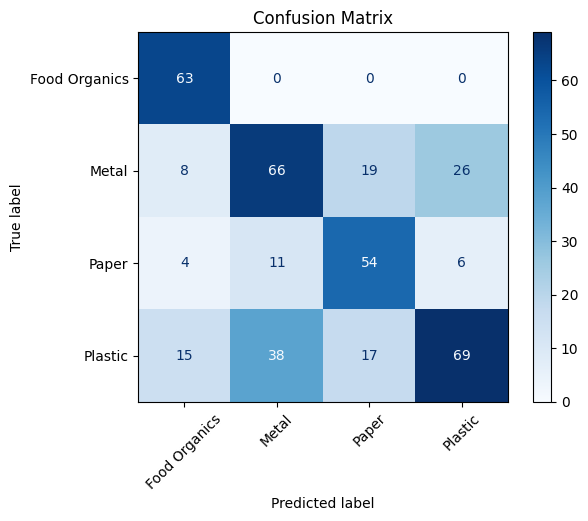

In [ ]:
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title("Confusion Matrix")
plt.show()

### Visualisasi Akurasi dan Loss

Visualisasi dilakukan untuk melihat perubahan nilai accuracy dan loss pada data training dan validation selama proses pelatihan model.

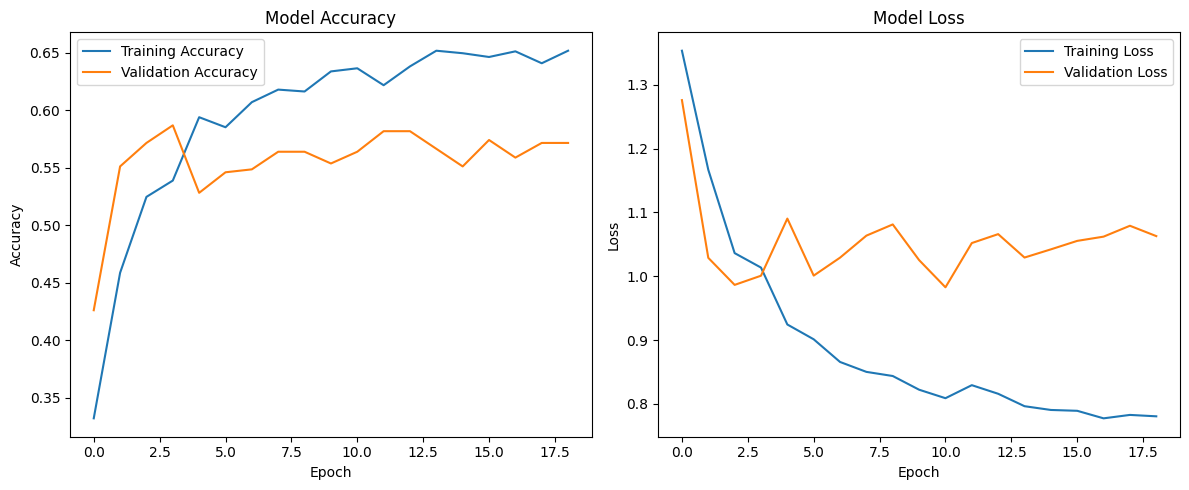

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### **7. Penyimpanan Model**

### Menyimpan Model

Model CNN yang telah dilatih disimpan dalam format `.keras` agar dapat digunakan kembali untuk proses prediksi gambar.

In [ ]:
model.save('waste_classifier_cnn.keras')

### Menyimpan Nama Kelas

Nama kelas disimpan dalam format JSON sebagai referensi label pada proses prediksi gambar.

In [ ]:
import json

with open('class_names.json', 'w') as f:
    json.dump(class_names, f)

### **8. Prediksi Gambar**

### Mengunggah Gambar

Gambar diunggah untuk menguji kemampuan model dalam mengklasifikasikan jenis sampah berdasarkan citra yang diberikan.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving images (1).jpeg to images (1).jpeg


### Preprocessing Gambar

Gambar yang diunggah diubah ke ukuran 224 × 224 piksel dan dinormalisasi ke rentang 0–1 agar sesuai dengan format input model.

In [ ]:
img_path = list(uploaded.keys())[0]

img = Image.open(img_path).convert('RGB')
img = img.resize((224, 224), Image.BILINEAR)

img_array = np.array(img, dtype='float32')
img_array = np.expand_dims(img_array, axis=0)

### Hasil Prediksi

Model menghasilkan prediksi berupa kategori sampah beserta tingkat kepercayaan (confidence) berdasarkan probabilitas tertinggi dari empat kelas.

In [ ]:
prediction = model.predict(img_array)

predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step


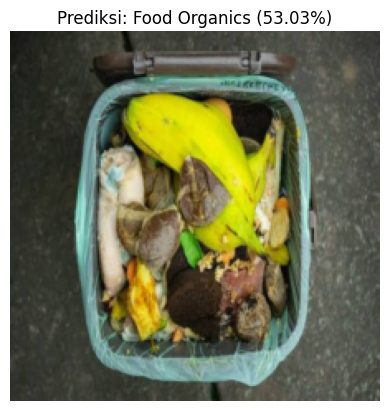

Hasil Prediksi: Food Organics
Confidence: 53.03%


In [ ]:
plt.imshow(img)
plt.axis('off')
plt.title(f'Prediksi: {predicted_class} ({confidence:.2f}%)')
plt.show()

print("Hasil Prediksi:", predicted_class)
print("Confidence:", f"{confidence:.2f}%")

In [ ]:
for i, category in enumerate(class_names):
    print(f"{category}: {prediction[0][i] * 100:.2f}%")

Food Organics: 53.03%
Metal: 17.42%
Paper: 28.04%
Plastic: 1.51%


## **9. Pemeriksaan File Model**

### Memeriksa File Model

Memeriksa keberadaan file model CNN dan file nama kelas yang telah disimpan untuk memastikan keduanya dapat digunakan kembali.

In [ ]:
import os

print("File Model:", os.path.exists('waste_classifier_cnn.keras'))
print("File Nama Kelas:", os.path.exists('class_names.json'))

File Model: True
File Nama Kelas: True


### Memuat Kembali Model

Model yang telah disimpan dimuat kembali untuk memastikan file model dapat digunakan pada proses prediksi berikutnya.

In [ ]:
loaded_model = tf.keras.models.load_model('waste_classifier_cnn.keras')

gambar_uji, _ = next(iter(test_ds))
sama = np.allclose(
    model.predict(gambar_uji, verbose=0),
    loaded_model.predict(gambar_uji, verbose=0),
    atol=1e-5
)
print("Hasil model tersimpan sama dengan model asli:", sama)

Hasil model tersimpan sama dengan model asli: True


In [ ]:
import shutil
from google.colab import files

model.save('waste_classifier_cnn.keras')
shutil.copy('waste_classifier_cnn.keras', 'model_final.keras')
files.download('model_final.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>